In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
path_dataset =os.path.join("/Users", "laurageneaulibourne", "Downloads", "S5", "Deep_learning", "project", "dataset")
path_train = os.path.join(path_dataset, "train.csv")

In [3]:
df_train = pd.read_csv(path_train)

In [4]:
target = "Diabetes_012"

In [6]:
# Binary Variables
bin_var = [
    c
    for c in df_train.columns
    if set(df_train[c].unique()).issubset({0.0, 1.0}) and c != target
]

# Continuous or Discrete Variables
cont_var = [c for c in df_train.columns if c not in bin_var and c != target]

/opt/anaconda3/envs/ia/lib/python3.10/site-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
/opt/anaconda3/envs/ia/lib/python3.10/site-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
/opt/anaconda3/envs/ia/lib/python3.10/site-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
/opt/anaconda3/envs/ia/lib/python3.10/site-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` withou

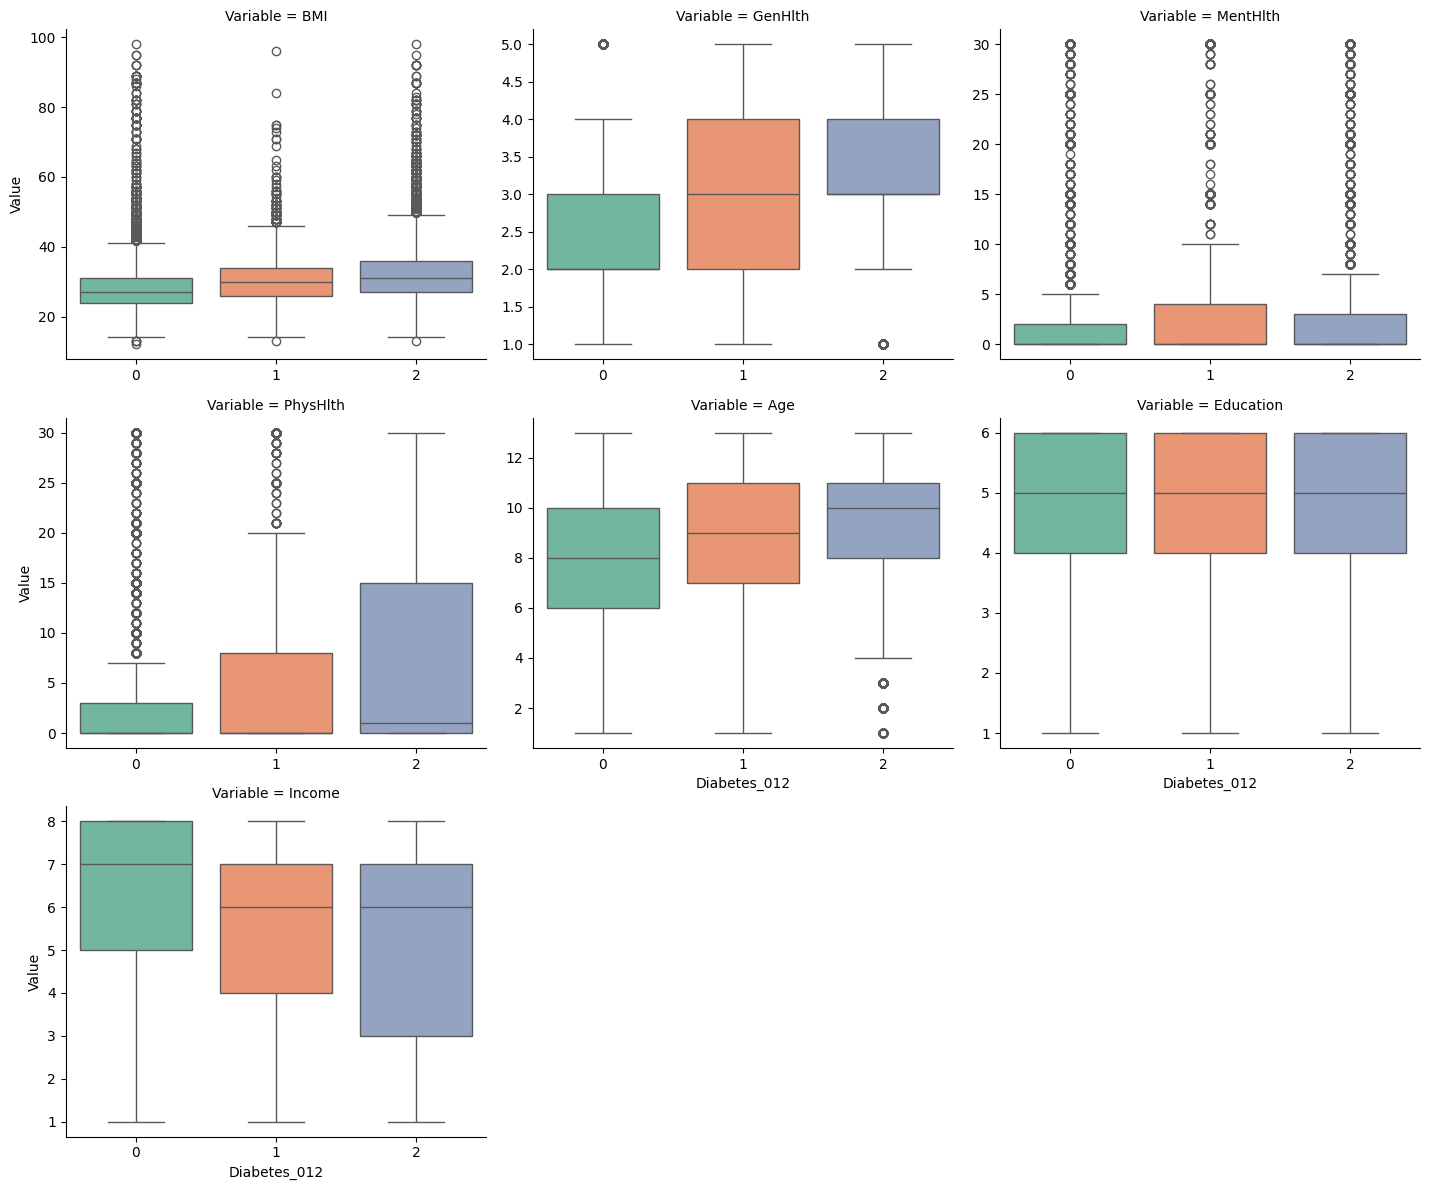

In [7]:

# Boxplots
df_cont = df_train.melt(
    id_vars=target,
    value_vars=cont_var,
    var_name="Variable",
    value_name="Value",
)
g1 = sns.FacetGrid(
    df_cont, col="Variable", col_wrap=3, sharey=False, height=4, aspect=1.2
)
g1.map_dataframe(sns.boxplot, x=target, y="Value", order=[0.0, 1.0, 2.0], palette="Set2")
for ax in g1.axes.flat:
  ax.tick_params(axis="x", labelbottom=True)
  ax.set_xticks([0, 1, 2])
  ax.set_xticklabels(["0", "1", "2"])
plt.tight_layout()
plt.show()



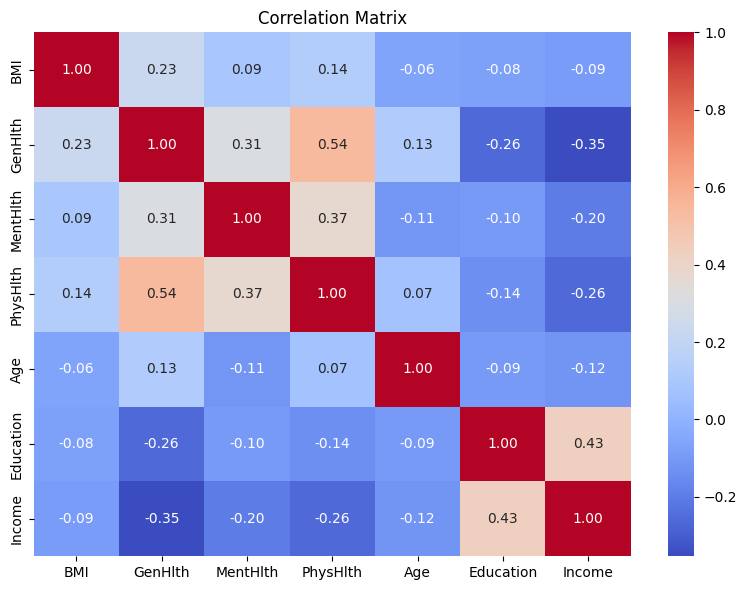

In [8]:

# Calcul de la corrélation (Pearson par défaut, ou 'spearman' si non linéaire / ordinal)
corr_matrix = df_train[cont_var].corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,  
    fmt=".2f", 
    cmap="coolwarm", 
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

/var/folders/sl/dj0_63hx63939c5t545hplkm0000gn/T/ipykernel_4727/3973874756.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pct.index, y=pct.values, ax=ax, palette="Set2")
/var/folders/sl/dj0_63hx63939c5t545hplkm0000gn/T/ipykernel_4727/3973874756.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pct.index, y=pct.values, ax=ax, palette="Set2")
/var/folders/sl/dj0_63hx63939c5t545hplkm0000gn/T/ipykernel_4727/3973874756.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pct.index, y=pct.values, ax=ax, palette="Set2")
/var/folders/

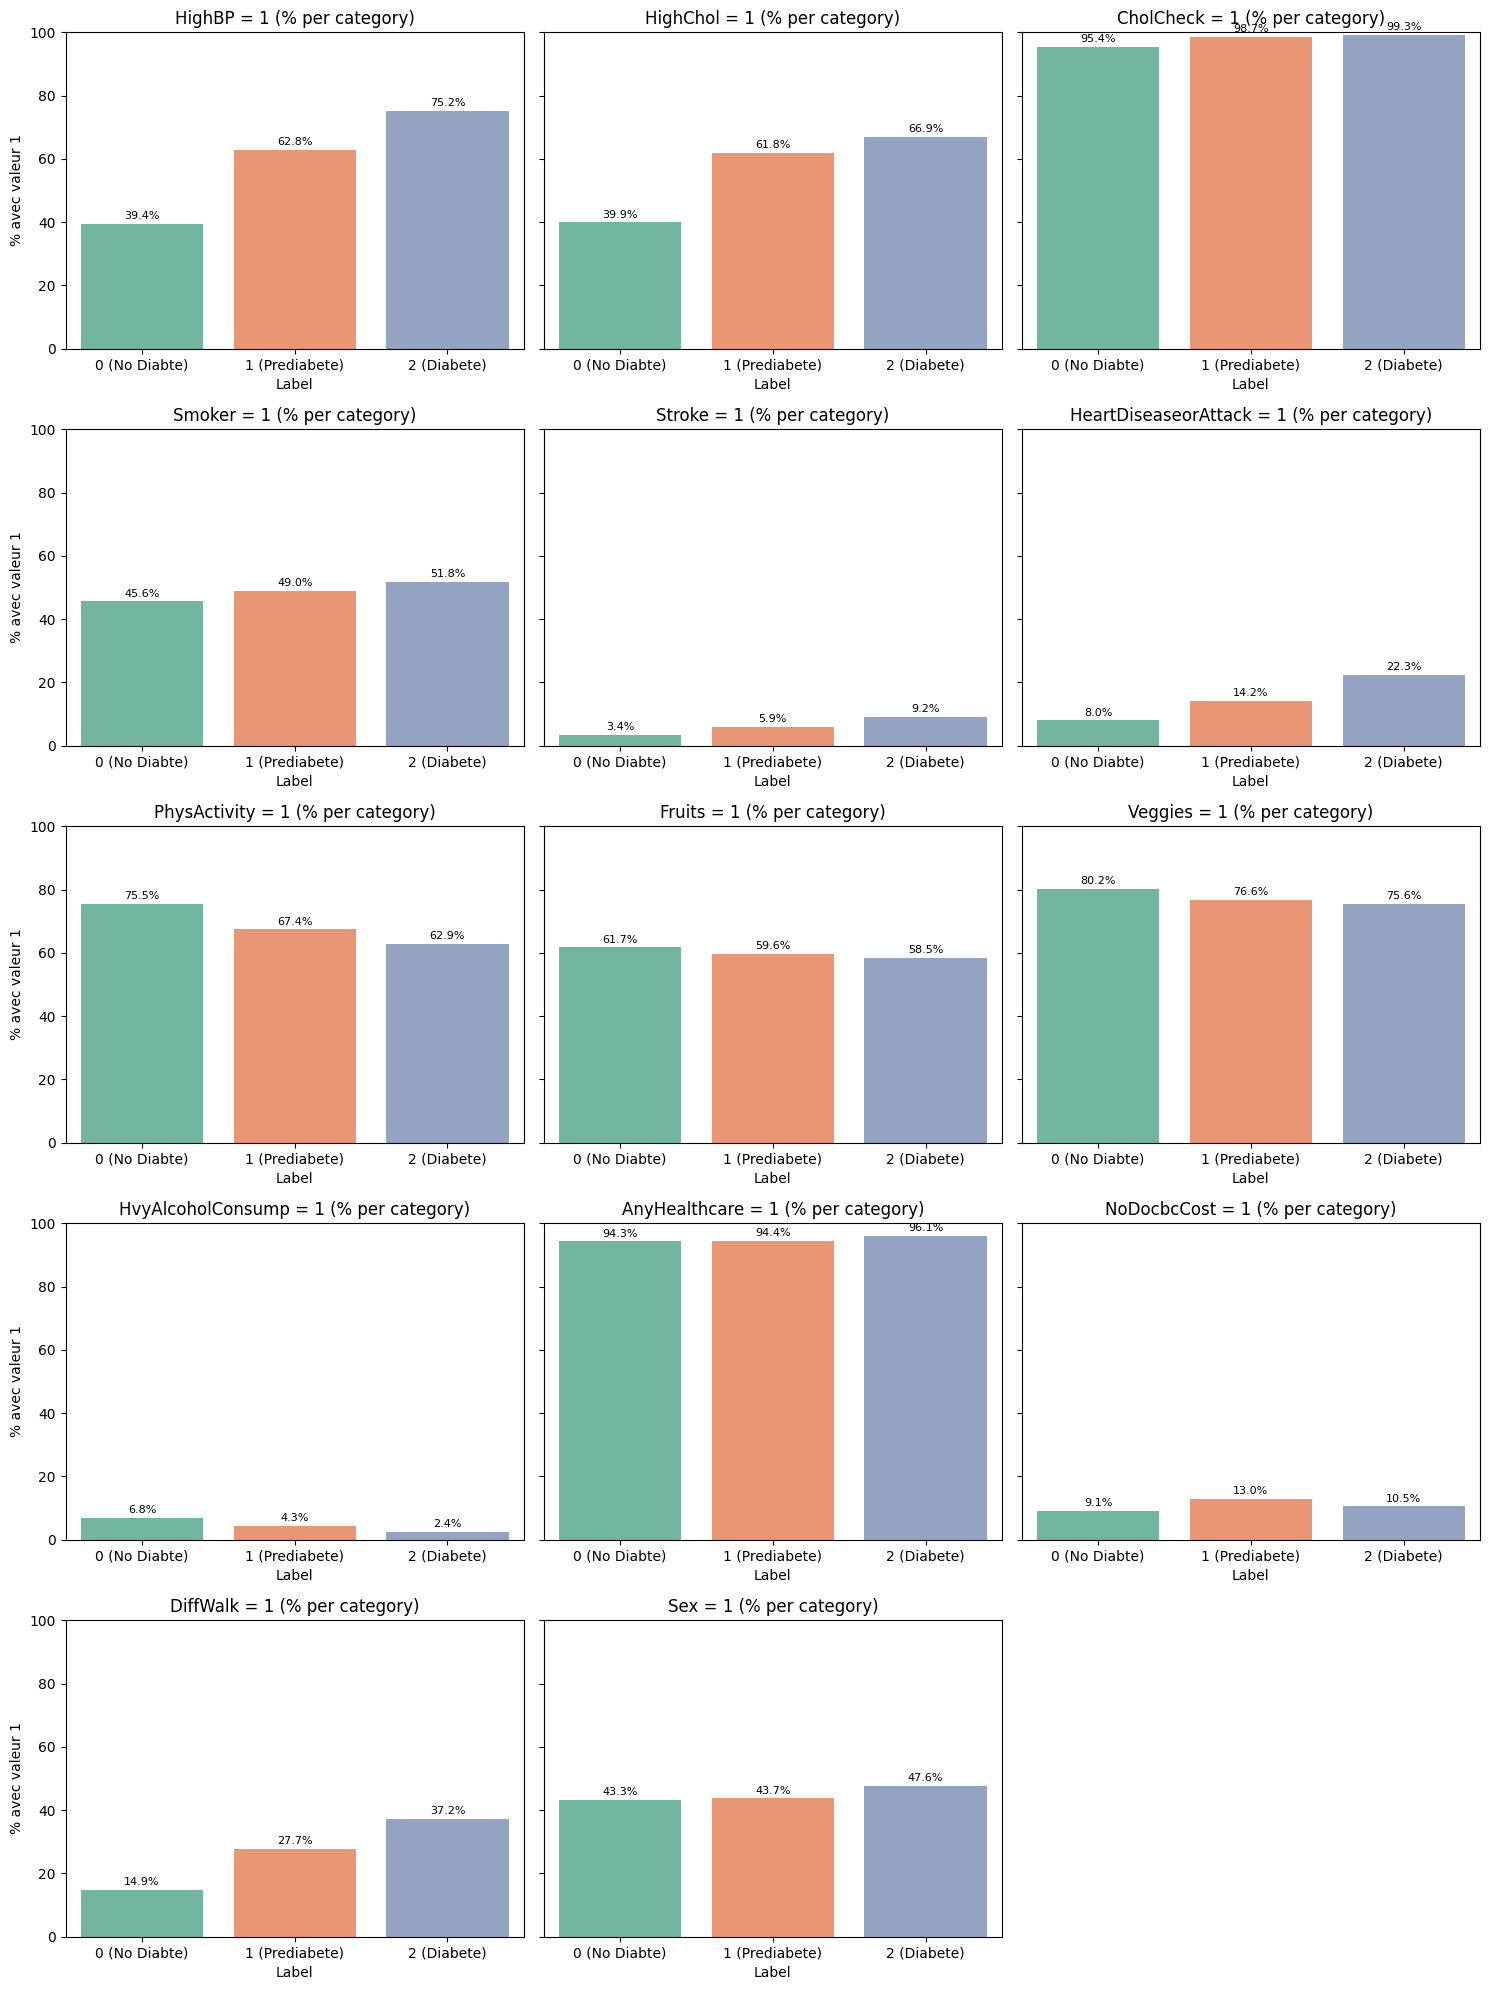

In [9]:
import math

label = [0.0, 1.0, 2.0]

total_par_classe = df_train[target].value_counts().reindex(label)

pct_by_col = {} # percentage per variable

for var in bin_var:
  var_1 = (
      df_train.loc[df_train[var] == 1, target]
      .value_counts()
      .reindex(label, fill_value=0)
  )
  pct = (var_1 / total_par_classe) * 100
  pct_by_col[var] = pct



n_cols = 3
n_rows = math.ceil(len(bin_var) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), sharey=True
)
axes = axes.flatten()

for ax, var in zip(axes, bin_var):
  pct = pct_by_col[var]

  sns.barplot(x=pct.index, y=pct.values, ax=ax, palette="Set2")
  ax.set_title(f"{var} = 1 (% per category)")
  ax.set_xticks([0, 1, 2])
  ax.set_xticklabels(["0 (No Diabte)", "1 (Prediabete)", "2 (Diabete)"])
  ax.set_xlabel("Label")
  ax.set_ylabel("% avec valeur 1")
  ax.set_ylim(0, 100)

  for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=8)

for ax in axes[len(bin_var) :]:
  ax.set_visible(False)

plt.tight_layout()
plt.show()